# Hyperbolic Cavity with $d=25$ nm and $R=40$ nm

This notebook presents the few-mode fitting and light–matter interaction analysis for the conical-hat resonance of a hyperbolic cavity with $d=25$ nm, $R=40$ nm, and an emitter height of $h=1$ nm. It follows the same overall workflow as the $R=10$ nm analysis, while retaining the additional comparisons, exceptional-point analysis, strong-coupling criteria, and dipole-dependent dynamics developed for this geometry.


## Tools and utilities


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
import cmasher as cmr

# Request 64-bit arithmetic from the optional fitting backend before it loads.
os.environ.setdefault('JAX_ENABLE_X64', 'True')
plt.style.use("https://johannesfeist.eu/misc/jf_cb.mplstyle")

import sys
sys.path.append('..')

from methods.plotcolored import plotcolored
from methods.tools import debye_e_nm

## Physical parameters


The calculations initially use a $1\,\mathrm{D}$ molecular vibration with an intrinsic linewidth of $0.04\,\mathrm{meV}$. The dipole moment is varied later when comparing the effective spectrum and time dynamics.


In [2]:
mu_D = 1.0 
mu_e_nm = mu_D * debye_e_nm
gamma_e_eV = 0.04 * 1e-3   # in eV

## Full spectral density

We first load the full cavity spectrum across the second Reststrahlen band. This broad spectrum is later used to separate the resonant few-mode contribution from the residual perturbative background. The final cells in this section also compare the cavity response with that of a planar hBN slab.

In [3]:
# import full spectral density
file_path = '../data/DAhS-25-40-1_full_Fp.txt'
dataB = np.loadtxt(file_path, skiprows=5)

In [4]:
# load frequency in THz
freq_full = np.array(dataB[:,0])

# Convert frequency in THz to the photon energy hbar*omega in eV.
w_full = freq_full / 241.799

# load Purcell factor
Fp_full = np.array(dataB[:,1])

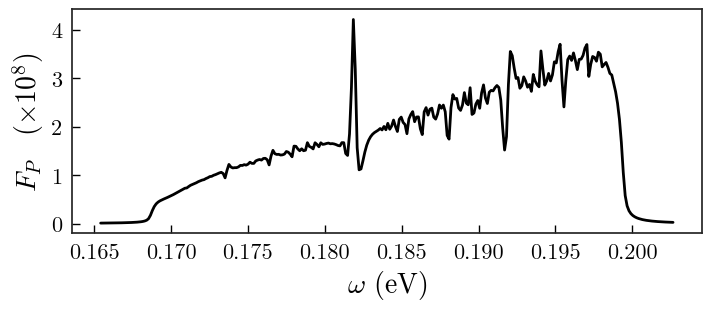

In [5]:
fig, ax = plt.subplots(figsize=(7,3))
ax.plot(w_full, Fp_full*1e-8)
ax.set_xlabel(r'$\omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$F_P \quad (\times 10^8)$', fontsize=20);

In [6]:
# Compute the dipole-moment-normalized spectral density for later use.

k0_full = 2.0 * np.pi / (1240 / w_full)
eps0 = 55.264 * 1e-3  # e^2 eV^-1 nm^-1
# compute free-space dipole-moment-normalized spectral density J_0(w) / mu^2
J0 = k0_full**3 / (6.0 * np.pi**2 * eps0)
# compute the dipole-moment-normalized spectral density J(w) / mu^2 
Jdivmu2_full = Fp_full * J0

### Comparison with a planar hBN slab

To distinguish the cavity-enhanced response from the underlying planar environment, we calculate the Purcell factor of a $25\,\mathrm{nm}$ hBN slab for the same dipole height and orientation. The slab calculation uses the scattering Green tensor and provides a reference background for the full cavity spectrum.


In [7]:
from methods.green_function import compute_ldos
from methods.hBN_permittivity import get_epsilon
from methods.hBN_permittivity import omega_LO_x_pure11b, omega_TO_x_pure11b
eps_2x, eps_2z = get_epsilon(hbn_type='pure') 

In [8]:
omega_ls = np.linspace(w_full[0], w_full[-1], 200) # eV
hdist = 1
dip_dir = np.array([0,0,1])
n_sio2 = 1.2  # approximate mid-IR refractive index
eps_1, eps_3 = 1.0, n_sio2**2 
eps_2x_val, eps_2z_val = eps_2x(omega_ls), eps_2z(omega_ls)
d = 25 #nm

kmax = 5e3
num_int = 1e4

ldos_res = compute_ldos(
    omega_ls=omega_ls,
    eps_1=eps_1,
    eps_2x=eps_2x_val,
    eps_2z=eps_2z_val,
    eps_3=eps_3,
    d=d,
    hdist=hdist,
    dip_dir=dip_dir,
    kmax=kmax,
    num_int=num_int
)

lam0 = 1240 / omega_ls
k0 = 2.0 * np.pi / lam0
im_nGn = k0 * np.sqrt(eps_1) / (6.0 * np.pi)
Fp = 1 + ldos_res['val'] / im_nGn

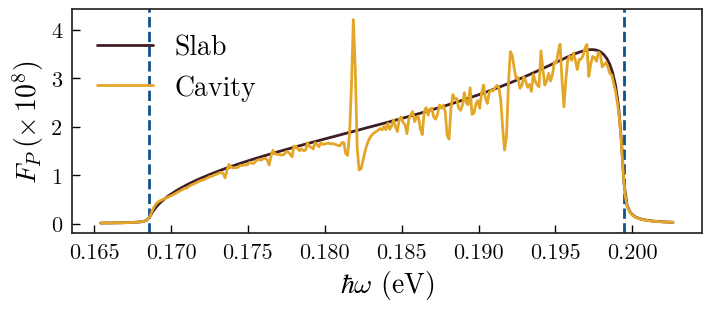

In [9]:
subset_colors = cmr.take_cmap_colors('cmr.rainforest', N=5, cmap_range=(0.2,0.8))
subset_colors2 = cmr.take_cmap_colors('cmr.amber', N=5, cmap_range=(0.2,0.8))

fig, ax = plt.subplots(figsize=(7,3))
ax.plot(omega_ls, Fp*1e-8, label='Slab', c=subset_colors2[0])
ax.plot(w_full, Fp_full*1e-8, label='Cavity', c=subset_colors2[-1])
ax.set_xlabel(r'$\hbar\omega \text{ (eV)}$', fontsize=20)
ax.set_ylabel(r'$F_P \, (\times \, 10^8)$', fontsize=20)
ax.legend(prop={'size': 20})

ax.axvline(omega_TO_x_pure11b, c=subset_colors[1], linestyle='--', lw=2, zorder=1)
ax.axvline(omega_LO_x_pure11b, c=subset_colors[1], linestyle='--', lw=2, zorder=1)

## Target spectral window and few-mode fit


The fitting data cover a narrow frequency window around the conical-hat resonance. We convert the calculated Purcell factor into the dipole-normalized spectral density used by the few-mode fitter.


In [10]:
file_path = '../data/DAhS-25-40-h_Fp_near44THz.txt'
dataB = np.loadtxt(file_path, skiprows=5)

In [11]:
# load frequency in THz
freq = np.array(dataB[:,0])

# I consider a specific configuration, that for h = 1 nm which corresponds to the second column
Fp = np.array(dataB[:,1])

In [12]:
# convert the frequency from THz to eV
w = freq / 241.799

k0 = 2.0 * np.pi / (1240 / w)
eps0 = 55.264 * 1e-3  # e^2 eV^-1 nm^-1

# compute dipole-moment-normalized free-space spectral density J(w) / mu^2
J0_divmu2 = k0**3 / (6.0 * np.pi**2 * eps0)
# compute free-space spectral density in eV^-1
J0 = k0**3 * mu_e_nm**2 / (6.0 * np.pi**2 * eps0)

# compute dipole-moment-normalized spectral density J(w) / mu^2
Jdivmu2 = Fp * J0_divmu2
# compute the spectral density J(w) in eV^-1
J = Fp * J0

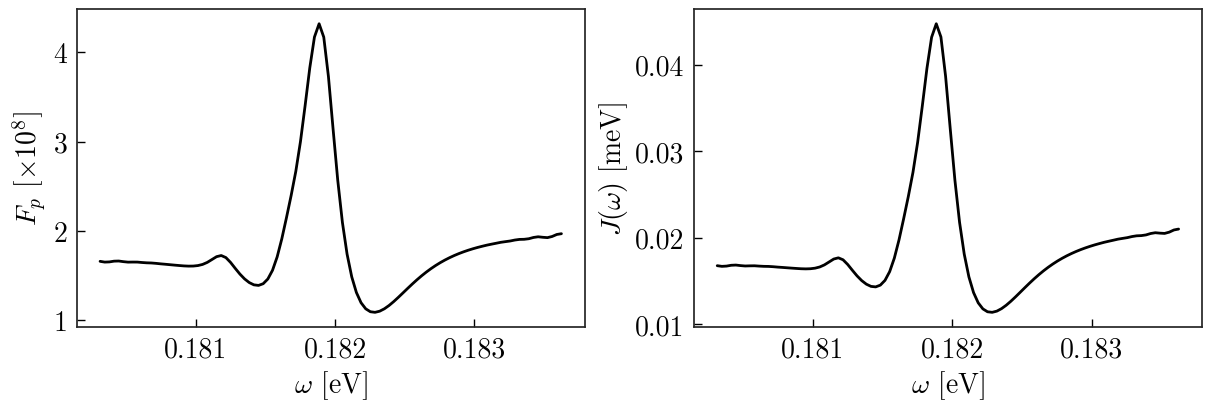

In [13]:
fig, ax = plt.subplots(figsize=(12,4), nrows=1, ncols=2)
ax[0].plot(w, Fp*1e-8, label='Fp')
ax[1].plot(w, J*1e3, label='J')

ax[0].tick_params(axis='both', labelsize=20)
ax[1].tick_params(axis='both', labelsize=20)

ax[0].set_xlabel(r'$\omega$ [eV]', fontsize=20)
ax[1].set_xlabel(r'$\omega$ [eV]', fontsize=20)
ax[0].set_ylabel(r'$F_p$ [$\times 10^8$]', fontsize=20)
ax[1].set_ylabel(r'$J(\omega)$ [meV]', fontsize=20);

### Electric Field Profile

We plot the corresponding electric field profile of this mode.

In [14]:
from scipy.interpolate import griddata
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

In [15]:
file_path = '../data/DAchS-25-40-1_field_profile.txt'
dataB = np.loadtxt(file_path, skiprows=8)

x, y, z = dataB[:,0], dataB[:,1], dataB[:,2]

In [16]:
xs = np.linspace(0.0, 50E-9, 400)
ys = np.linspace(-30E-9, 10E-9, 400)
X, Y = np.meshgrid(xs, ys)
Z = griddata((x, y), z, (X, Y), method='cubic')  # or 'linear'

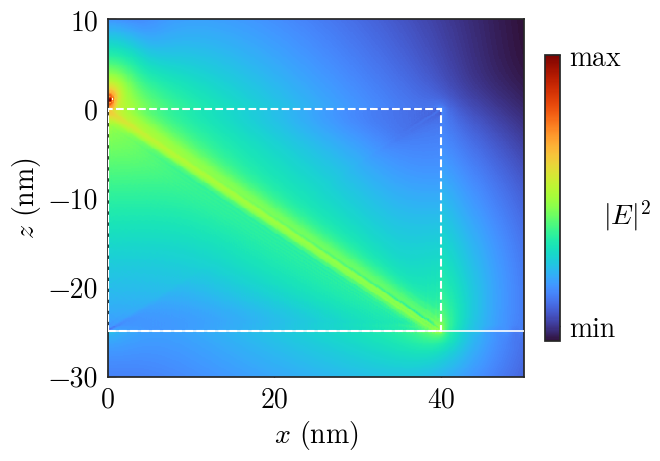

In [17]:
fig, ax = plt.subplots()
pcm = ax.pcolormesh(X*1e9, Y*1e9, Z, norm=LogNorm(), rasterized=True)
cbar = fig.colorbar(pcm, ax=ax, shrink=0.8)
cbar.ax.set_ylabel(r'$|E|^2$', rotation=0, fontsize=20)
cbar.set_ticks([1e-0, Z.max()])
cbar.set_ticklabels(['min', 'max'], fontsize=20) 

ax.set_xlabel(r'$x \text{ (nm)}$', fontsize=20)
ax.set_ylabel(r'$z \text{ (nm)}$', fontsize=20)
ax.tick_params(axis='both', labelsize=20)

ax.axhline(y=-25, color='white', lw=1.2, zorder=3)

cavity = Rectangle((0, -25), 40, 25,
                   linewidth=1.5,
                   edgecolor='white',
                   facecolor='none',
                   linestyle='--',
                   zorder=3)
ax.add_patch(cavity);

### Few-mode fitting procedure


In [18]:
# import custom module for applying few-mode fitting
from methods.apply_few_mode import FewModeFit

We initialize a seven-mode model with approximate resonance energies, linewidths, and emitter-mode couplings. These values are starting points only; the numerical optimization determines the final coupled-mode parameters. The fit is performed on the dipole-normalized spectral density $J(\omega)/\mu^2$, allowing the resulting couplings to be reused for different molecular dipole moments.


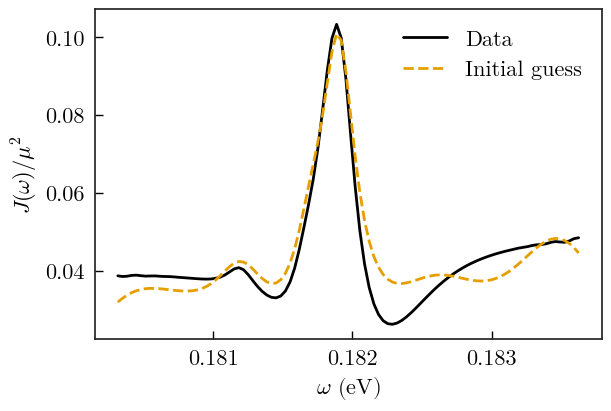

In [19]:
H = np.diag([0.1804, 0.1808, 0.1812, 0.1817, 0.1819, 0.1826, 0.1835])
Nm = H.shape[0]
K = np.r_[10e-4, 10e-4, 5e-4, 3e-4, 3e-4, 10e-4, 10e-4]
g = np.r_[[6E-3, 4E-3, 4E-3, 3E-3, 6E-3, 6E-3, 8E-3]].reshape(1, Nm)

fmc = FewModeFit(w, Jdivmu2, H, K, g)
fmc.initialize();

We now optimize the model parameters to reproduce the calculated spectral density.

Fit error: 0.00353365


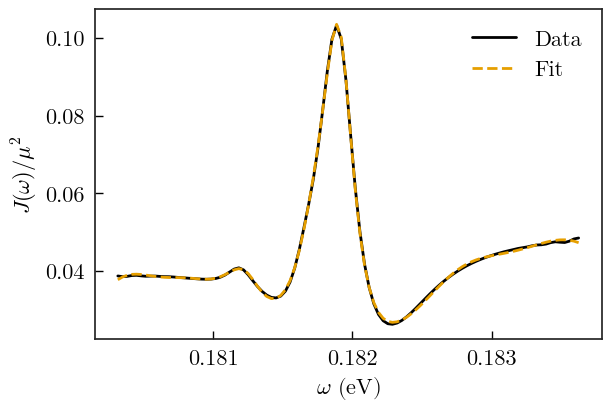

In [20]:
fmc.fit();

After fitting, we diagonalize the lossy mode Hamiltonian $\tilde{\mathbf H}=\mathbf H-i\,\mathrm{diag}(\boldsymbol\kappa)/2$. Its complex eigenfrequencies determine the resonance positions and quality factors, while the transformed couplings determine the normalized effective mode volumes.


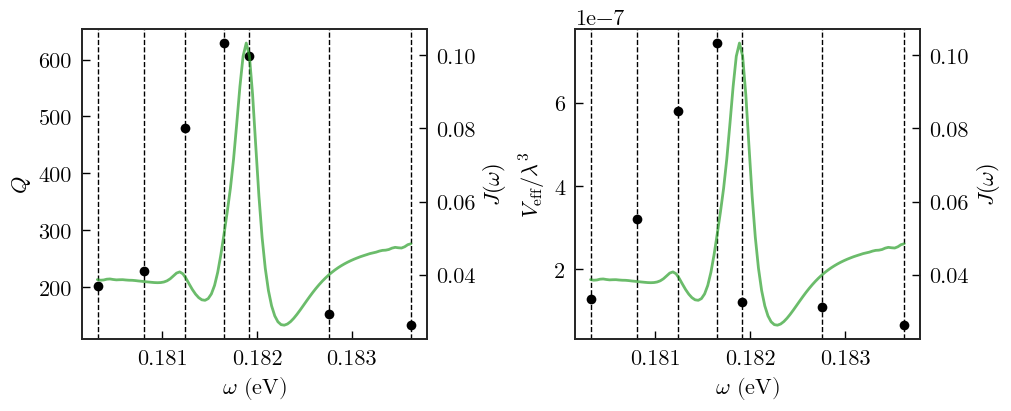

In [21]:
Omega, Q, Veff_norm = fmc.compute_figures_of_merit()

We interpolate the dipole-normalized fitted spectral density across the second Reststrahlen band. This provides a smooth representation of the resonant few-mode contribution for the perturbative separation below.


In [22]:
Jfit_interp_func = fmc.create_interpolator(w_min=0.165, w_max=0.203)
w_interp = np.linspace(0.165, 0.203, 400)
Jfit_interp = Jfit_interp_func(w_interp)

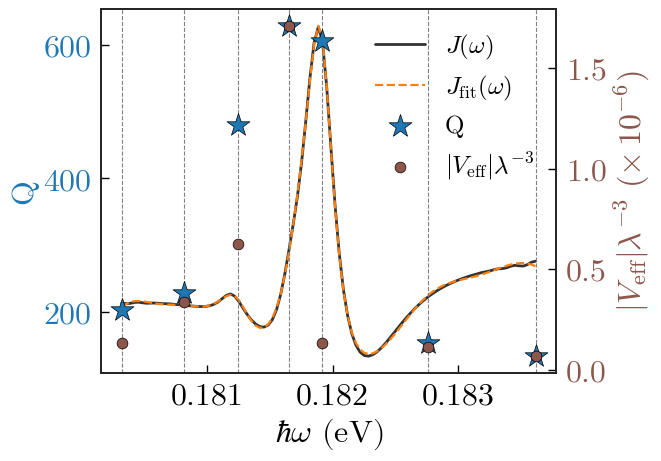

In [23]:
fig, ax1 = plt.subplots()

Jfit_interp_full = Jfit_interp_func(w) * mu_e_nm**2 

# Colors
c_Q     = '#1f77b4'   # blue, for Q (left axis)
c_V     = '#8c564b'   # brown, for V_eff (right axis)
c_true  = '#333333'   # near-black, true J
c_fit   = '#ff7f0e'   # orange, few-mode fit

# Spectral density curves (use a hidden 3rd axis so they don't conflict with left scale)
ax_J = ax1.twinx()
ax_J.plot(w, J, color=c_true, lw=2, label=r'$J(\omega)$')
ax_J.plot(w, Jfit_interp_full,  color=c_fit, lw=1.6, ls='--', label=r'$J_{\text{fit}}(\omega)$')
ax_J.set_yticks([])              # hide ticks
ax_J.spines['right'].set_visible(False)
ax_J.set_zorder(1)               # behind markers

# Vertical guides at mode frequencies (optional, very faint)
for wi in np.real(Omega):
    ax1.axvline(wi, color='gray', lw=0.8, ls='--', alpha=1.0, zorder=0)

# Q on left axis
ax1.scatter(np.real(Omega), Q, marker='*', s=300,
            color=c_Q, edgecolor='black', lw=0.5,
            label='Q', zorder=3)
ax1.set_xlabel(r'$\hbar \omega$ (eV)', fontsize=23)
ax1.set_ylabel('Q', color=c_Q, fontsize=23)
ax1.tick_params(axis='x', labelsize=23)
ax1.tick_params(axis='y', labelcolor=c_Q, labelsize=23)
ax1.set_zorder(2)
ax1.patch.set_visible(False)     # let ax_J show through

# V_eff on right axis
ax2 = ax1.twinx()
ax2.scatter(np.real(Omega), np.abs(Veff_norm)*1e6, marker='o', s=60,
            color=c_V, edgecolor='black', lw=0.5,
            label=r'$|V_\mathrm{eff}| \lambda^{-3}$', zorder=3)
ax2.set_ylabel(r'$|V_\mathrm{eff}| \lambda^{-3} \,\, (\times \, 10^{-6})$', color=c_V, fontsize=23)
ax2.tick_params(axis='y', labelcolor=c_V, labelsize=23)
ax2.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# Combined legend
handles = (ax_J.get_lines() +
           [ax1.collections[0], ax2.collections[0]])
labels  = [h.get_label() for h in handles]
ax1.legend(handles, labels, frameon=False, fontsize=18)

In [49]:
# Complex light-matter couplings normalized by the dipole moment; these are
# equivalently proportional to the single-polariton electric fields.
g_tilde = fmc.g_tilde

# Recover the fitted coupled-mode parameters as NumPy arrays.
H, kappas, gs = fmc.fitted_parameters()

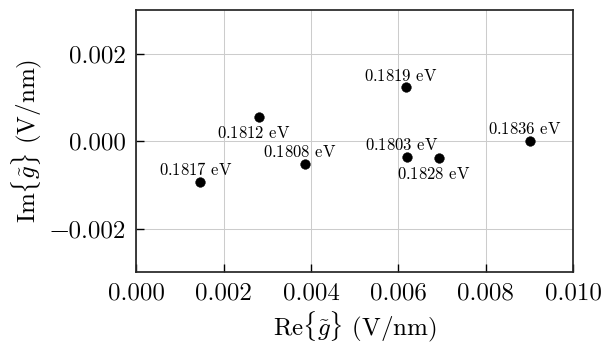

In [25]:
x = np.real(g_tilde)
y = np.imag(g_tilde)

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(x, y)
ax.set_xlabel(r'$\text{Re}\{\tilde{g}\} \text{ (V/nm)}$', fontsize=18)
ax.set_ylabel(r'$\text{Im}\{\tilde{g}\} \text{ (V/nm)}$', fontsize=18)
ax.tick_params(axis="both", labelsize=18)
labels = [r'${%.4f} \text{ eV}$' % wi for wi in np.real(Omega)]
for i, txt in enumerate(labels):

    if i == 2 or i == 5:
        plt.annotate(txt, (x[i], y[i]), xytext=(-30, -15), textcoords='offset points', fontsize=12)
    else:
        plt.annotate(txt, (x[i], y[i]), xytext=(-30, 5), textcoords='offset points', fontsize=12)

ax.set_xlim(0.00, 0.010)
ax.set_ylim(-0.003, 0.003)
ax.set_aspect('equal', adjustable='box')
ax.grid()

### Contribution of the conical-hat mode

The full response arises from interference among the diagonalized lossy modes. To inspect the conical-hat resonance itself, we plot the contribution of the selected diagonalized mode using its complex resonance energy and complex transformed coupling.


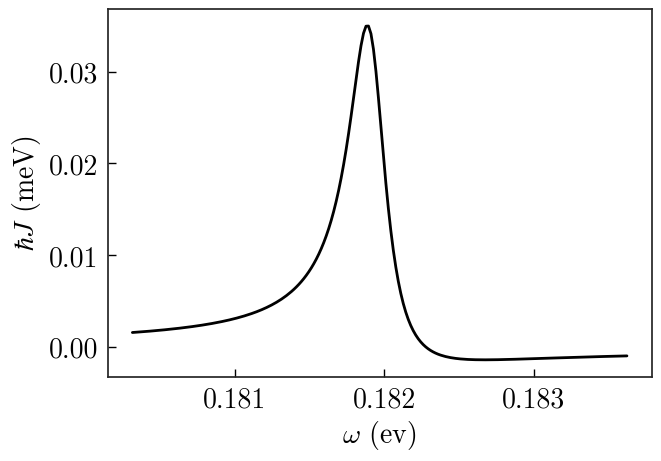

In [26]:
fig, ax = plt.subplots()

i = 4
wjf_ls = np.linspace(w[0], w[-1], 200)
Jf = 1.0 / np.pi * np.imag(g_tilde[i]**2 / (Omega[i] - wjf_ls)) * mu_e_nm**2
ax.plot(wjf_ls, Jf*1e3)

ax.set_xlabel(r'$\omega \text{ (ev)}$', fontsize=20)
ax.set_ylabel(r'$\hbar J \text{ (meV)}$', fontsize=20)
ax.tick_params(axis='both', labelsize=20)

We collect the fitted spectrum, coupled-mode parameters, and diagonalized-mode figures of merit in one dictionary. Saving this object allows the light–matter analysis to be reproduced without rerunning the optimization.


In [27]:
data = {
    'fit': {
        'w': w, 
        'J': J, 
        'w_interp': w_interp, 
        'Jfit_interp': Jfit_interp
    },    
    'coupled_modes': {
        'H': H, 
        'kappas': kappas, 
        'g': gs
    },
    'uncoupled_modes': {
        'Omega': Omega,
        'Q': Q,
        'Veff_norm': Veff_norm,
        'gs': g_tilde
    }
}

with open('few_mode_fits/DAchS-25-40-1_7modes_fit.pickle', 'wb') as handle:
    pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)

## Load saved few-mode fitting results (optional)

Run this section only when loading a previously saved fit—for example, to skip the optimization and proceed directly to the light–matter analysis. When running the notebook from the beginning, these cells simply reload the results saved above.

In [57]:
# load data
filename = 'few_mode_fits/DAchS-25-40-1_7modes_fit.pickle'
with open(filename, 'rb') as handle:
    data = pickle.load(handle)

In [58]:
w, J = data['fit']['w'], data['fit']['J']
w_interp, Jfit_interp = data['fit']['w_interp'], data['fit']['Jfit_interp']
H = data['coupled_modes']['H']
kappas = data['coupled_modes']['kappas']
gs = data['coupled_modes']['g']
Nm = kappas.shape[0]

## Perturbative/non-perturbative separation

The fitted few-mode model describes the resonant part of the electromagnetic environment non-perturbatively. We evaluate this fit on the full frequency grid and subtract it from the complete spectral density. The residual $\Delta J(\omega)=J_\mathrm{full}(\omega)-J_\mathrm{fit}(\omega)$ is then included perturbatively through its Lamb shift and decay rate.


In [28]:
from scipy.interpolate import CubicSpline
from methods.perturbative import lamb_shift_fm, decay_rate_fm

In [29]:
# Reconstruct the saved, dipole-normalized fit on the full frequency grid.
spline = CubicSpline(w_interp, Jfit_interp, bc_type='not-a-knot', extrapolate=False)

def Jfit_func(w):
    res = spline(w)
    return np.where(np.isnan(res), 0.0, res)

# Restore the physical spectral densities for the selected dipole moment.
J_full = Jdivmu2_full * mu_e_nm**2 
Jfit = Jfit_func(w_full) * mu_e_nm**2
diff = J_full - Jfit 

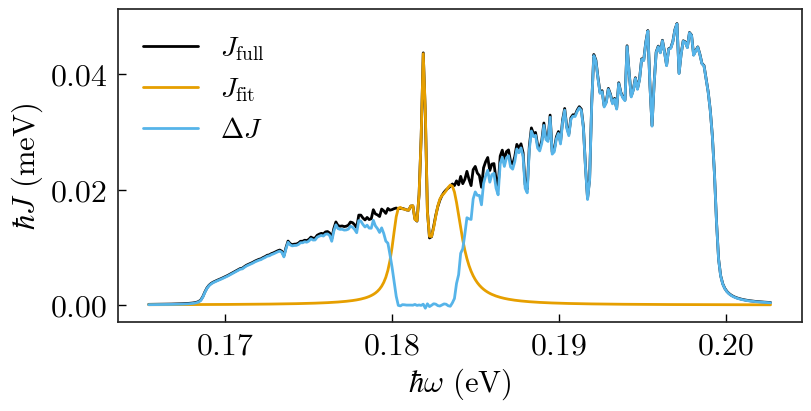

In [30]:
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(w_full, J_full*1e3, label=r'$J_{\text{full}}$')
ax.plot(w_full, Jfit*1e3, label=r'$J_{\text{fit}}$')
ax.plot(w_full, diff*1e3, label=r'$\Delta J$')
ax.set_xlabel(r'$\hbar\omega \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\hbar J \text{ (meV)}$', fontsize=22)
ax.legend(prop={'size': 20})
ax.tick_params(axis='both', labelsize=23);

The residual spectral density produces the Lamb shift $\Delta(\omega_e)$. We use it to map the externally specified bare transition energy to the frequency entering the effective Hamiltonian, $\tilde{\omega}_e=\omega_e-\Delta(\omega_e)$.


In [31]:
we_ls = np.linspace(w[0], w[-1], 50)

diffs = []
for wi in we_ls:
    val = lamb_shift_fm(wi, w_full, diff)
    diffs.append(val)

ldif = np.array(diffs)
we_new = we_ls - ldif

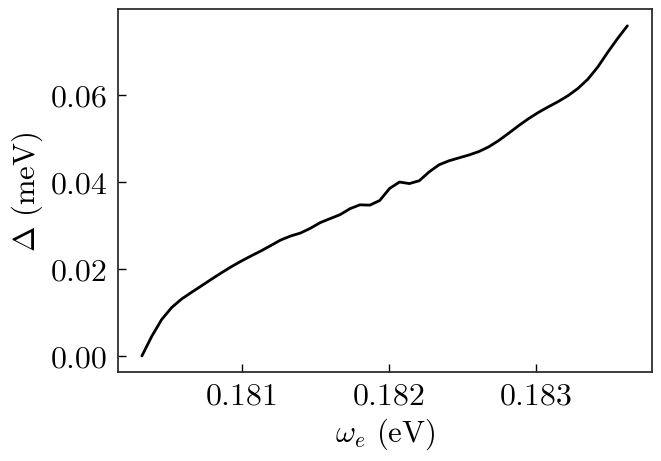

In [32]:
fig, ax = plt.subplots()
ax.plot(we_ls, ldif*1e3)
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\Delta \text{ (meV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)

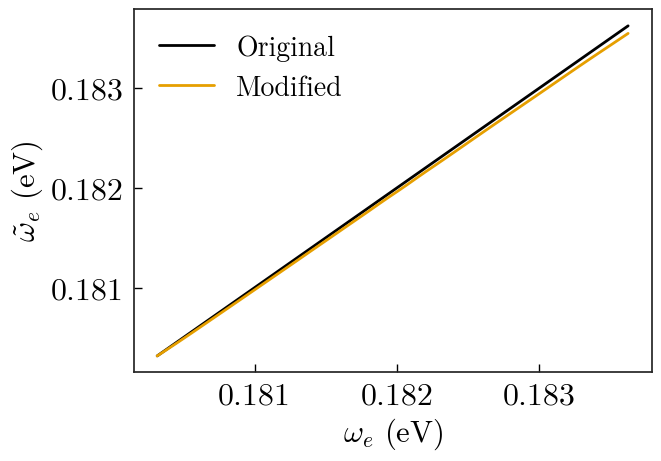

In [33]:
fig, ax = plt.subplots()
ax.plot(we_ls, we_ls, label='Original')
ax.plot(we_ls, we_new, label='Modified')
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\tilde{\omega}_e \text{ (eV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 20});

The same residual produces the frequency-dependent perturbative decay rate

$$\gamma_\mathrm{pert}(\omega_e)=2\pi\,\Delta J(\omega_e).$$

The total rate supplied to the effective model is the sum of this contribution and the intrinsic molecular linewidth.


In [34]:
gamma_e_new = decay_rate_fm(we_ls, w_full, diff)

## Spectrum of the effective Hamiltonian

We calculate the spectrum of the effective non-Hermitian Hamiltonian

$$\hat{\mathcal H}_\mathrm{eff}=\hat H'_\mathrm{S}-\frac{i}{2}\sum_i\kappa_i\hat a_i^\dagger\hat a_i-\frac{i}{2}[\gamma_e+\gamma_\mathrm{pert}(\omega_e)]\hat b^\dagger\hat b.$$

Here, $\hat H'_\mathrm{S}$ contains the fitted few-mode Hamiltonian, dipole-scaled light–matter couplings, and the Lamb-shift-corrected emitter energy $\tilde{\omega}_e$.


In [35]:
from methods.mastereq import MasterEquationQtp

The effective quantum model is constructed from the fitted coupled-mode Hamiltonian, mode decay rates, and emitter-mode couplings. Restricting the Hilbert space to a single excitation is sufficient for the linear-response dynamics considered here.

In [36]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);

We sweep the bare emitter transition across the fitted window. At each point, the corresponding Lamb-shift-corrected energy and total decay rate are used to diagonalize the effective Hamiltonian, revealing the hybridized branches and avoided crossings.


In [37]:
vals, vecs = meq.get_Heff_dispersion(
    we_new, mu=mu_e_nm, gamma_e=gamma_e_new+gamma_e_eV
)

The horizontal coordinate is the bare emitter energy $\omega_e$, while the effective Hamiltonian uses $\tilde{\omega}_e$. Each branch is coloured by its emitter weight $|c_e|^2$, distinguishing predominantly photonic modes from branches with appreciable molecular character.


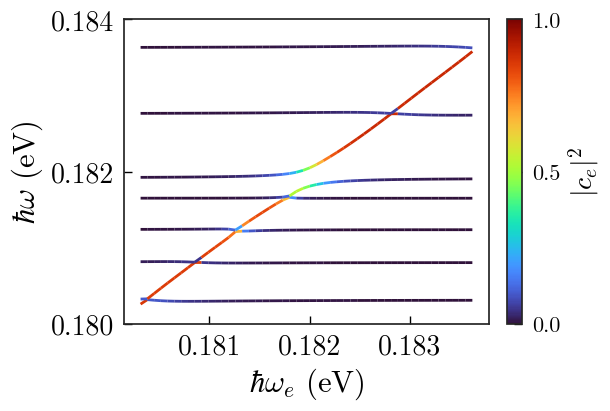

In [38]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots(figsize=(6,4))
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in the corresponding eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\hbar \omega_e \text{ (eV)}$", fontsize=22)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=22)
cb = plt.colorbar(im, ax=ax)
cb.set_label("$|c_e|^2$", fontsize=20)
ax.tick_params(axis='both', labelsize=20)
ax.set_yticks([0.180,0.182,0.184])

cb.set_ticks([0,0.5,1])

In [39]:
# Locate the bare emitter energy at which the selected branches have their minimum splitting.
spl = vals[:, 6].real - vals[:, 5].real
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([0.00023538]), array([0.18193556]))

In [41]:
# Perturbative contribution to the emitter decay rate at resonance.
gamma_e_new_at_res = gamma_e_new[we_indx]

For the selected branches, the calculated Rabi splitting is $\Omega_R=0.24\,\mathrm{meV}$ near $\omega_e=0.1819\,\mathrm{eV}$.


At the minimum splitting, we inspect the photonic-mode composition of the two hybridized eigenstates. This identifies which fitted modes participate in the avoided crossing.


In [42]:
# Use the same sweep index selected by the minimum-splitting analysis.
w_ind = we_indx

n_comp = [i for i in range(1, vecs.shape[1])]


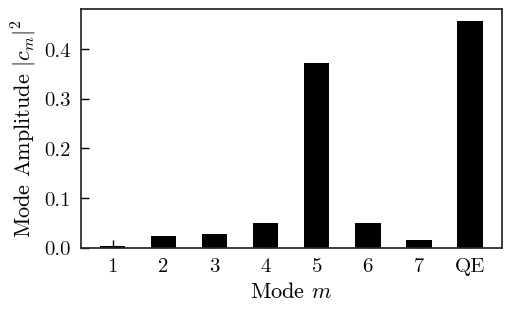

In [43]:
# Width of the bars
width = 0.5

fig, ax = plt.subplots(figsize=(5,3))
i = 5
eig_i = np.flip(np.squeeze(abs(vecs[w_ind,1:,i])**2))
ax.bar(np.array(n_comp), eig_i, width, 
        label=r"$\text{Eigenstate } %i$" % i)

ax.tick_params(axis='both', labelsize=15)
ax.set_xlabel(r'$\text{Mode } m$', fontsize=16)
ax.set_ylabel(r'$\text{Mode Amplitude } |c_{m}|^2$', fontsize=16)
ax.set_xticks(n_comp)
ax.set_xticklabels([f'{j}' for j in n_comp[:-1]] + ['QE']);

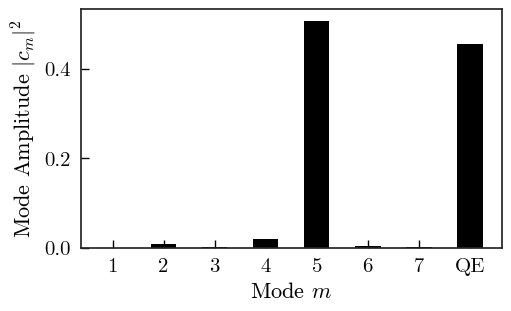

In [44]:
# Width of the bars
width = 0.5

fig, ax = plt.subplots(figsize=(5,3))
i = 6
eig_i = np.flip(np.squeeze(abs(vecs[w_ind,1:,i])**2))
ax.bar(np.array(n_comp), eig_i, width, 
        label=r"$\text{Eigenstate } %i$" % i)

ax.tick_params(axis='both', labelsize=15)
ax.set_xlabel(r'$\text{Mode } m$', fontsize=16)
ax.set_ylabel(r'$\text{Mode Amplitude } |c_{m}|^2$', fontsize=16)
ax.set_xticks(n_comp)
ax.set_xticklabels([f'{j}' for j in n_comp[:-1]] + ['QE']);

### Exceptional point and strong-coupling criteria

We fix the emitter near the conical-hat resonance and vary its dipole moment. Tracking the two relevant eigenvalues reveals the exceptional-point region associated with the interference-induced character of the fitted modes.


In [45]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas)

# choose an emitter frequency where the 
# 1-mode JC is approximately correct
we = np.array([0.1819])
mu_ls = np.linspace(0, 0.03, 30)

omegas_EP = []
for mu in mu_ls:
    vl, _ = meq.get_Heff_dispersion(we, mu=mu)
    omegas_EP.append(vl)
omegas_EP = np.array(omegas_EP)

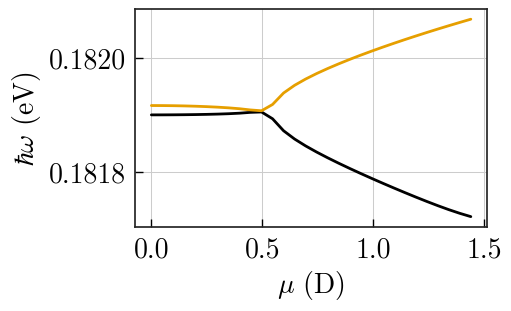

In [46]:
fig, ax = plt.subplots(figsize=(5,3))
for i in range(5, 7): 
    ax.plot(mu_ls / debye_e_nm, np.real(omegas_EP[:,0,i]))
ax.grid()
#ax.set_title(r'$\omega_e = %.5f \text{ eV}$' % we[0], fontsize=20)
ax.set_xlabel(r'$\mu \text{ (D)}$', fontsize=20)
ax.set_ylabel(r'$\hbar \omega \text{ (eV)}$', fontsize=20)
ax.tick_params(axis='both', labelsize=20)

The nearly zero-detuning case above identifies the exceptional-point region.


We next evaluate two complementary strong-coupling criteria using the complex coupling of the selected conical-hat mode, its linewidth, and the intrinsic molecular linewidth. The resulting thresholds are estimates based on this reduced single-mode characterization; the full seven-mode spectrum above remains the primary calculation.


In [54]:
# as taken from before
g_tilde4 = g_tilde[4] # V/nm
gamma_c = np.real(Omega[4]) / Q[4] # eV
gamma_e = 0.04 * 1e-3       # eV

In [61]:
mu_ls = np.linspace(0.2, 1.2, 20) # Debye
mu_ls = mu_ls * debye_e_nm

res = {'C1': [], 'C2': []}
for mu_i in mu_ls:
    Omega_R = np.real(g_tilde4) * mu_i * 2
    C1 = Omega_R / (np.abs(gamma_c-gamma_e)/2)
    C2 = Omega_R / np.sqrt(gamma_c**2 / 2 + gamma_e**2 / 2) 
    res['C1'].append(C1)
    res['C2'].append(C2)

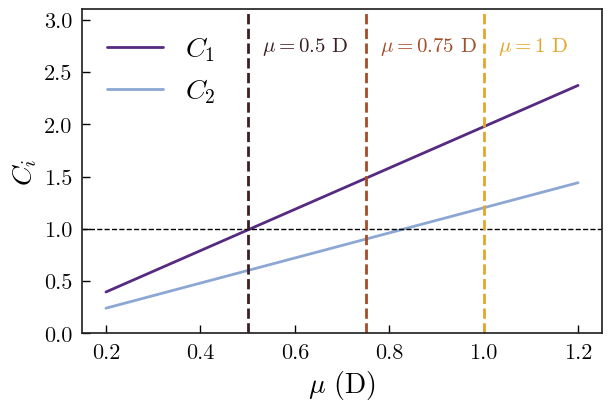

In [62]:
subset_colors = cmr.take_cmap_colors('cmr.amber', N=3, cmap_range=(0.2,0.8))
subset_colors2 = cmr.take_cmap_colors('cmr.amethyst', N=2, cmap_range=(0.3,0.7))

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(mu_ls / debye_e_nm, res['C1'], label=r'$C_1$', c=subset_colors2[0])
ax.plot(mu_ls / debye_e_nm, res['C2'], label=r'$C_2$', c=subset_colors2[1])
ax.axhline(1, linestyle='--', lw=1)
ax.legend(prop={'size': 20})

ax.axvline(0.5, linestyle='--', color=subset_colors[0])
ax.text(0.5+0.03, 2.7, r'$\mu = 0.5 \text{ D}$', fontsize=15, color=subset_colors[0])

ax.axvline(0.75, linestyle='--', color=subset_colors[1])
ax.text(0.75+0.03, 2.7, r'$\mu = 0.75 \text{ D}$', fontsize=15, color=subset_colors[1])

ax.axvline(1.0, linestyle='--', color=subset_colors[2])
ax.text(1.0+0.03, 2.7, r'$\mu = 1 \text{ D}$', fontsize=15, color=subset_colors[2])

ax.set_ylim(0, 3.1)

ax.set_xlabel(r'$\mu \text{ (D)}$', fontsize=20)
ax.set_ylabel(r'$C_i$', fontsize=20);

In [63]:
# compute threshold for C1
C1_vals = np.array(res['C1'])
dC1_vals = np.abs(C1_vals - 1.0)
C1_indx = np.where(dC1_vals == np.min(dC1_vals))
print("For C1:\t", mu_ls[C1_indx][0] / debye_e_nm)

# compute threshold for C2
C2_vals = np.array(res['C2'])
dC2_vals = np.abs(C2_vals - 1.0)
C2_indx = np.where(dC2_vals == np.min(dC2_vals))
print("For C2:\t", mu_ls[C2_indx][0] / debye_e_nm)

For C1:	 0.5157894736842106
For C2:	 0.831578947368421


## Time dynamics

Finally, we propagate an initially excited emitter coupled to all seven fitted modes.

In [64]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [65]:
# Tune the emitter to the energy selected from the avoided-crossing analysis.
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_new[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_new_at_res+gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(9, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [66]:
tsfs, sol = meq.solve(t_max=4e4, n_t=1000)

(1e-08, 100)

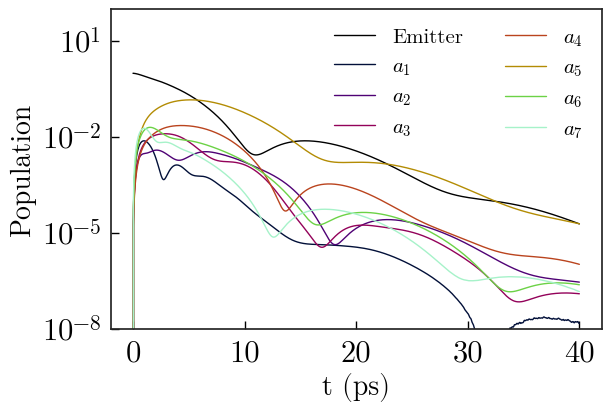

In [67]:
subset_colors = cmr.take_cmap_colors('cmr.chroma', N=7, cmap_range=(0.1,0.9))
#subset_colors2 = cmr.take_cmap_colors('cmr.amber', N=5, cmap_range=(0.2,0.8))

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter", lw=1.0)
for i in range(len(sol.expect)-1):
    ax.plot(tsfs*1e-3, sol.expect[i], label=r"$a_%i$" % (i+1), c=subset_colors[i], lw=1.0)
ax.set_xlabel("t (ps)", fontsize=20)
ax.set_ylabel("Population", fontsize=20)
ax.tick_params(axis="both", labelsize=22)
ax.legend(prop={'size': 15}, ncols=2)
ax.set_yscale("log")
ax.set_ylim(1e-8, 100)

## Spectrum and Dynamics for $\mu=0.75\,\mathrm{D}$

In [68]:
mu_D = 0.75
mu_e_nm = mu_D * debye_e_nm

In [69]:
# construct the physical spectral density (and the difference) with the current dipole moment
J_full = Jdivmu2_full * mu_e_nm**2 
Jfit = Jfit_func(w_full) * mu_e_nm**2
diff = J_full - Jfit 

In [70]:
we_ls = np.linspace(w[0], w[-1], 50)

diffs = []
for wi in we_ls:
    val = lamb_shift_fm(wi, w_full, diff)
    diffs.append(val)

ldif = np.array(diffs)
we_new = we_ls - ldif

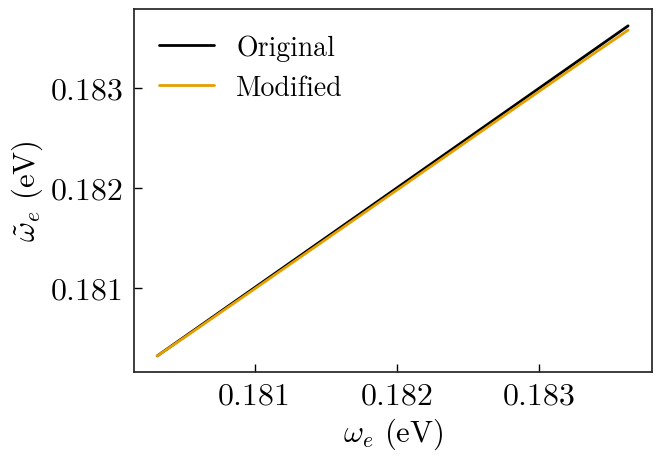

In [71]:
fig, ax = plt.subplots()
ax.plot(we_ls, we_ls, label='Original')
ax.plot(we_ls, we_new, label='Modified')
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\tilde{\omega}_e \text{ (eV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 20});

In [72]:
# compute the perturbative decay rate
gamma_e_new = decay_rate_fm(we_ls, w_full, diff)

In [73]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);
vals, vecs = meq.get_Heff_dispersion(we_new, mu=mu_e_nm, gamma_e=gamma_e_new+gamma_e_eV)

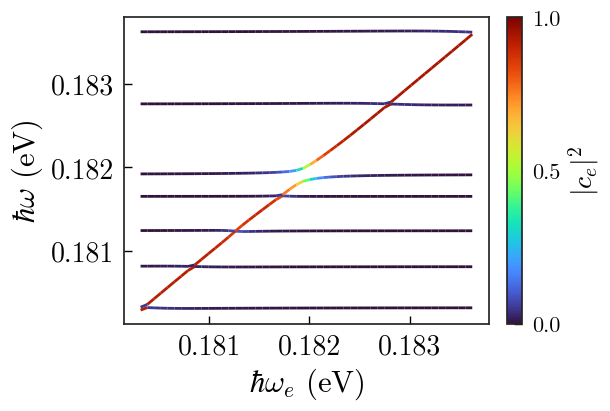

In [74]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots(figsize=(6,4))
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in the corresponding eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\hbar \omega_e \text{ (eV)}$", fontsize=22)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=22)
cb = plt.colorbar(im, ax=ax)
cb.set_label("$|c_e|^2$", fontsize=20)
ax.tick_params(axis='both', labelsize=20)
#ax.set_yticks([0.1855,0.1865,0.1875])

cb.set_ticks([0,0.5,1])

In [75]:
# Locate the emitter energy at which the selected branches have their minimum splitting.
spl = vals[:,6].real - vals[:,5].real
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([0.00015683]), array([0.18193556]))

In [76]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [77]:
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_new[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_new[we_indx]+gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(9, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [78]:
tsfs, sol = meq.solve(t_max=4e4, n_t=10000)

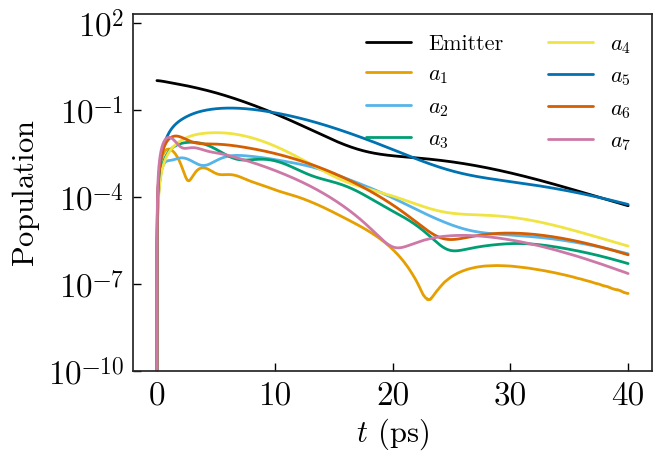

In [81]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(ncol=2);
ax.set_yscale('log')
ax.set_ylim(1e-10, 200);

## Spectrum and Dynamics for $\mu=0.50\,\mathrm{D}$


In [82]:
mu_D = 0.50
mu_e_nm = mu_D * debye_e_nm

In [83]:
# construct the physical spectral density (and the difference) with the current dipole moment
J_full = Jdivmu2_full * mu_e_nm**2 
Jfit = Jfit_func(w_full) * mu_e_nm**2
diff = J_full - Jfit 

In [84]:
we_ls = np.linspace(w[0], w[-1], 50)

diffs = []
for wi in we_ls:
    val = lamb_shift_fm(wi, w_full, diff)
    diffs.append(val)

ldif = np.array(diffs)
we_new = we_ls - ldif

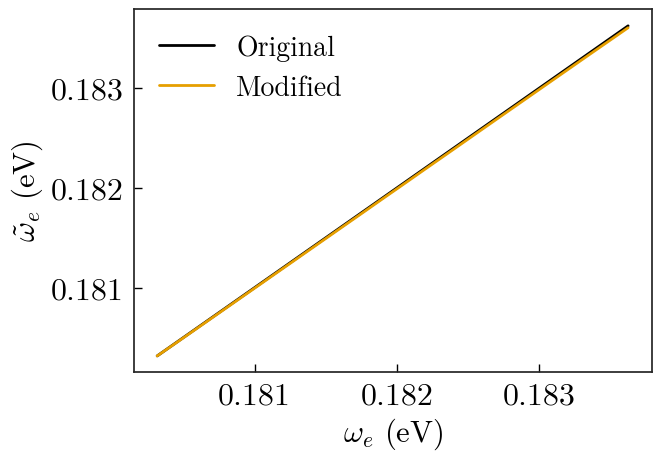

In [85]:
fig, ax = plt.subplots()
ax.plot(we_ls, we_ls, label='Original')
ax.plot(we_ls, we_new, label='Modified')
ax.set_xlabel(r'$\omega_e \text{ (eV)}$', fontsize=22)
ax.set_ylabel(r'$\tilde{\omega}_e \text{ (eV)}$', fontsize=22)
ax.tick_params(axis='both', labelsize=23)
ax.legend(prop={'size': 20});

In [86]:
# compute the perturbative decay rate
gamma_e_new = decay_rate_fm(we_ls, w_full, diff)

In [87]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)
meq.provide_fm_pars(H, gs, kappas);
vals, vecs = meq.get_Heff_dispersion(we_new, mu=mu_e_nm, gamma_e=gamma_e_new+gamma_e_eV)

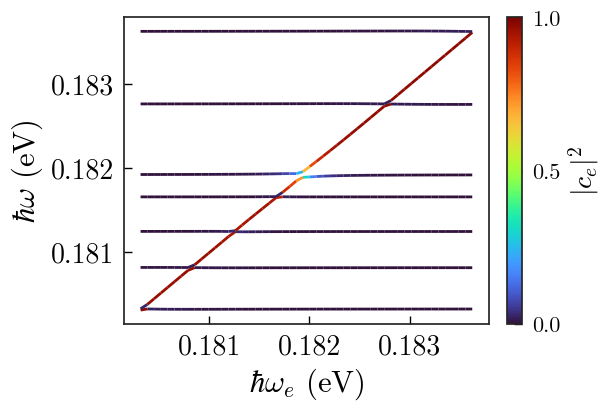

In [88]:
# plotcolored wants a plot axis as input, generate an empty figure and axis
fig, ax = plt.subplots(figsize=(6,4))
# make sure all lines are colored with the same mapping to the data range, from 0 to 1
norm = plt.matplotlib.colors.Normalize(0,1)
for ii in range(1, vals.shape[1]):
    # Colour each branch by the emitter population in the corresponding eigenvector.
    im = plotcolored(ax, we_ls, vals[:,ii].real, abs(vecs[:,1,ii])**2, norm=norm)
# plotcolored does not automatically rescale the axis to the data limits, do it now
ax.autoscale()
ax.set_xlabel(r"$\hbar \omega_e \text{ (eV)}$", fontsize=22)
ax.set_ylabel(r"$\hbar \omega \text{ (eV)}$", fontsize=22)
cb = plt.colorbar(im, ax=ax)
cb.set_label("$|c_e|^2$", fontsize=20)
ax.tick_params(axis='both', labelsize=20)
#ax.set_yticks([0.1855,0.1865,0.1875])

cb.set_ticks([0,0.5,1])

In [89]:
# Locate the emitter energy at which the selected branches have their minimum splitting.
spl = vals[:,6].real - vals[:,5].real
we_indx = np.where(spl == np.min(spl))
spl[we_indx], we_ls[we_indx]

(array([6.67954619e-05]), array([0.18193556]))

In [90]:
meq = MasterEquationQtp(Nm=Nm, Ne=1, Nexc=1)

In [91]:
meq.provide_fm_pars(H, gs, kappas)
meq.set_qe_pars(omega_e=we_new[we_indx][0], mu=mu_e_nm, gamma_e=gamma_e_new[we_indx]+gamma_e_eV)
meq.setup_ops()
meq.initial_state()

Quantum object: dims=[[2, 2, 2, 2, 2, 2, 2, 2], [1]], shape=(9, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [92]:
tsfs, sol = meq.solve(t_max=4e4, n_t=10000)

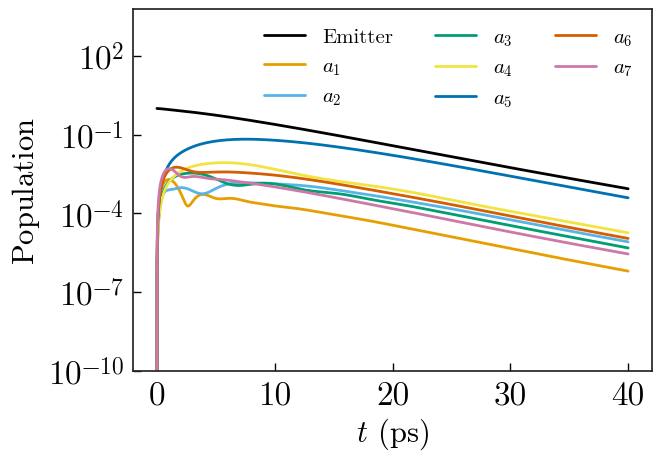

In [93]:
fig, ax = plt.subplots()
ax.plot(tsfs*1e-3, sol.expect[-1], label="Emitter")
for ii in range(Nm):
    ax.plot(tsfs*1e-3, sol.expect[ii], label=r"$a_{%i}$" % (ii+1))
ax.set_xlabel(r"$t \text{ (ps)}$", fontsize=22)
ax.set_ylabel(r"$\text{Population}$", fontsize=22)
ax.tick_params(axis='both', labelsize=24)
ax.legend(prop={'size': 15}, ncols=3)
ax.set_yscale('log')
ax.set_ylim(1e-10, 6000);